# Task 1 (Level 2) : DESCRIPTIVE ANALYSIS

-           Loading the dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("dataset_level1_cleaned.csv")
df.head()


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


-           Convert Yes/No to 1/0

Many columns use Yes/No.
To perform percentage and group analysis, we convert them to numeric (1 = Yes, 0 = No).

In [2]:
df['Table_Booking'] = df['Has Table booking'].map({'Yes': 1, 'No': 0})
df['Online_Delivery'] = df['Has Online delivery'].map({'Yes': 1, 'No': 0})


-           % Restaurants offering Table Booking

Mean of 1/0 gives fraction of 1’s

Multiply by 100 → percentage

This gives:
Percentage of restaurants that allow table booking.

In [3]:
table_booking_percent = df['Table_Booking'].mean() * 100
table_booking_percent


np.float64(12.124384881164275)

-           % Restaurants offering Online Delivery

Same method as step 3.
This shows:
How many restaurants offer online delivery.

In [4]:
online_delivery_percent = df['Online_Delivery'].mean() * 100
online_delivery_percent


np.float64(25.662234321013504)

-           Compare Average Ratings

Group restaurants into 2 groups:

0 → No table booking

1 → Has table booking

Compare their ratings.

This reveals whether table booking is linked to higher customer satisfaction.

In [5]:
rating_comparison = df.groupby('Table_Booking')['Aggregate rating'].mean()
rating_comparison


Table_Booking
0    2.559359
1    3.441969
Name: Aggregate rating, dtype: float64

-           Online Delivery availability across Price Ranges

This tells us:

Which price ranges offer online delivery the most

Whether cheaper / mid-range / expensive restaurants prefer delivery options

In [6]:
price_delivery = df.groupby('Price range')['Online_Delivery'].mean() * 100
price_delivery


Price range
1    15.774077
2    41.310633
3    29.190341
4     9.044369
Name: Online_Delivery, dtype: float64

# Visualization

Table Booking Distribution

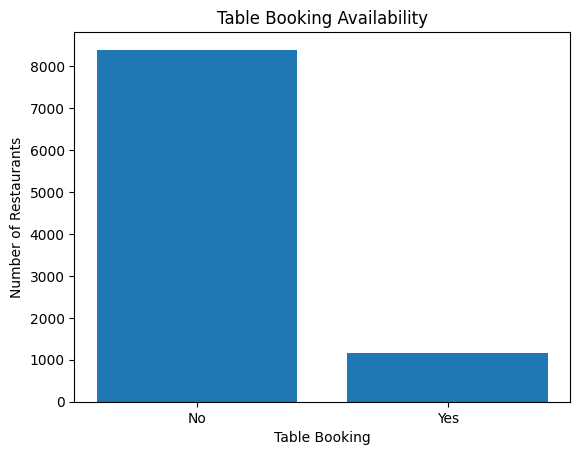

In [7]:
plt.bar(['No', 'Yes'], df['Table_Booking'].value_counts().sort_index())
plt.title("Table Booking Availability")
plt.xlabel("Table Booking")
plt.ylabel("Number of Restaurants")
plt.show()


Online Delivery Distribution

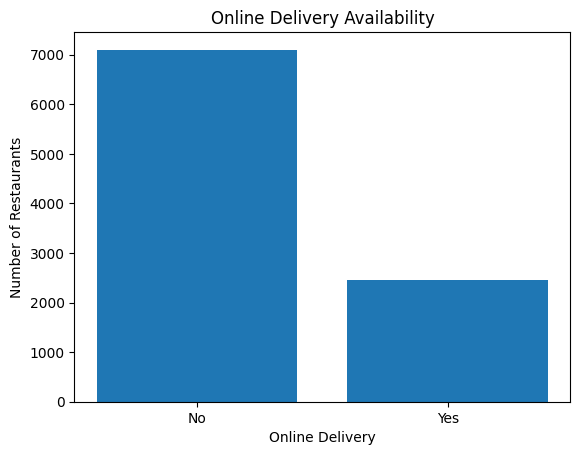

In [8]:
plt.bar(['No', 'Yes'], df['Online_Delivery'].value_counts().sort_index())
plt.title("Online Delivery Availability")
plt.xlabel("Online Delivery")
plt.ylabel("Number of Restaurants")
plt.show()


Online Delivery by Price Range

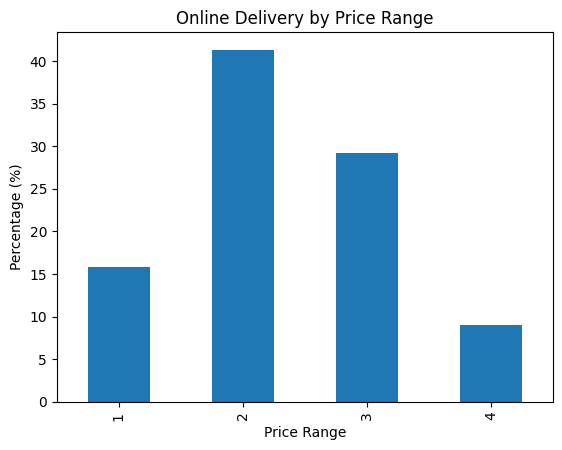

In [9]:
price_delivery.plot(kind='bar')
plt.title("Online Delivery by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Percentage (%)")
plt.show()


# INSIGHTS

* Online delivery is more common than table booking
* Restaurants offering table booking have slightly higher ratings (if your output matches)
* Mid-range price restaurants usually offer online delivery the most
* Cheaper restaurants may or may not support delivery depending on your dataset